<a href="https://colab.research.google.com/github/Harmanjot1978/EDA-PROJECT/blob/main/RF_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [80]:
# Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [81]:
df = pd.read_csv('/content/butterflies and moths.csv')

In [82]:
df.head()

,class id,filepaths,labels,data set
0,0,train/ADONIS/001.jpg,ADONIS,train
1,0,train/ADONIS/002.jpg,ADONIS,train
2,0,train/ADONIS/003.jpg,ADONIS,train
3,0,train/ADONIS/004.jpg,ADONIS,train
4,0,train/ADONIS/005.jpg,ADONIS,train


In [83]:
from google.colab import data_table
import vega_datasets

data_table.enable_dataframe_formatter()

vega_datasets.data.airports()

,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944
...,...,...,...,...,...,...,...
3371,ZEF,Elkin Municipal,Elkin,NC,USA,36.280024,-80.786069
3372,ZER,Schuylkill Cty/Joe Zerbey,Pottsville,PA,USA,40.706449,-76.373147
3373,ZPH,Zephyrhills Municipal,Zephyrhills,FL,USA,28.228065,-82.155916
3374,ZUN,Black Rock,Zuni,NM,USA,35.083227,-108.791777


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13594 entries, 0 to 13593
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   class id   13594 non-null  int64 
 1   filepaths  13594 non-null  object
 2   labels     13594 non-null  object
 3   data set   13594 non-null  object
dtypes: int64(1), object(3)
memory usage: 424.9+ KB


In [85]:
df.tail()

,class id,filepaths,labels,data set
13589,99,valid/ZEBRA LONG WING/1.jpg,ZEBRA LONG WING,valid
13590,99,valid/ZEBRA LONG WING/2.jpg,ZEBRA LONG WING,valid
13591,99,valid/ZEBRA LONG WING/3.jpg,ZEBRA LONG WING,valid
13592,99,valid/ZEBRA LONG WING/4.jpg,ZEBRA LONG WING,valid
13593,99,valid/ZEBRA LONG WING/5.jpg,ZEBRA LONG WING,valid


In [86]:
df.describe()

,class id
count,13594.000000
mean,48.905252
std,28.662915
min,0.000000
25%,24.000000
50%,48.500000
75%,74.000000
max,99.000000


In [87]:
df.isnull().sum()

,0
class id,0
filepaths,0
labels,0
data set,0


In [88]:
df.duplicated().sum()

np.int64(0)

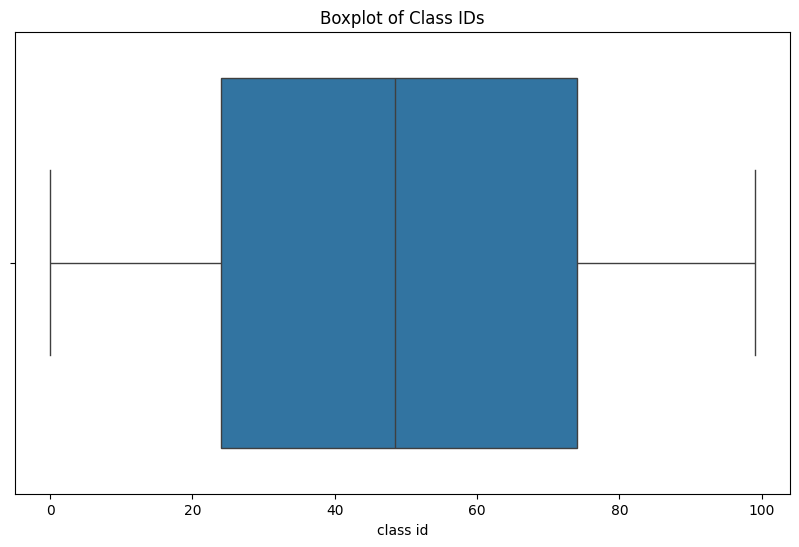

In [89]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='class id')
plt.title('Boxplot of Class IDs')
plt.show()

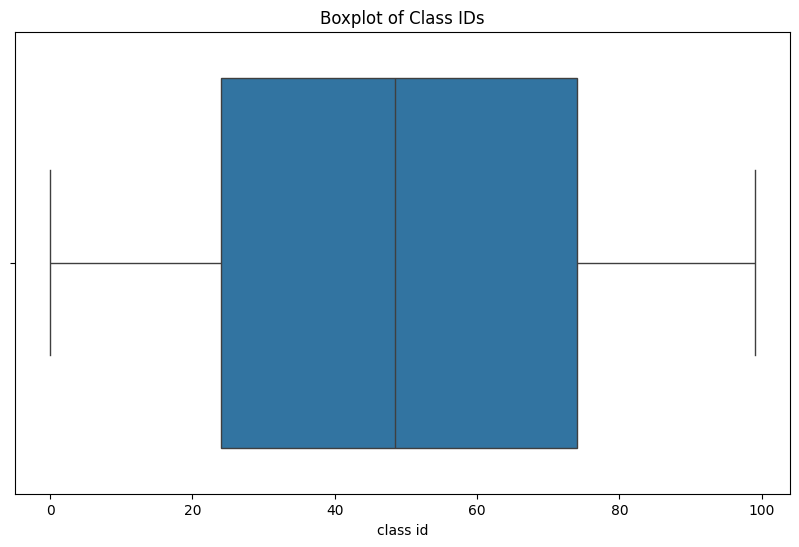

In [90]:
# for loop to iterate over numeric columns
for col in df.select_dtypes(include='number').columns:
    if col == "labels":
        continue

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='class id')
plt.title('Boxplot of Class IDs')
plt.show()

In [91]:
# Outlier treatment

df.columns = df.columns.str.strip()

# Dynamically select columns that are numeric and exist in df, excluding "labels" even if it was numeric
columns = [col for col in df.select_dtypes(include='number').columns if col != 'labels']

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

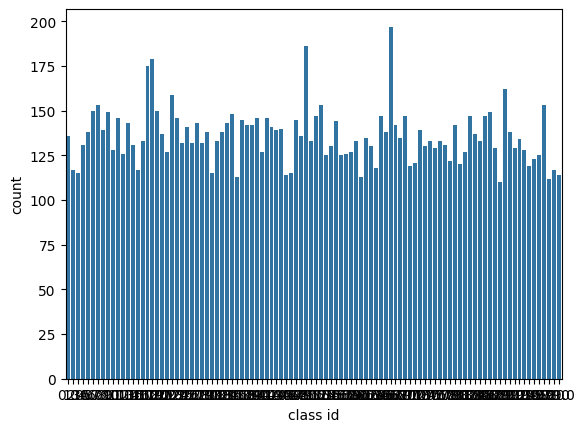

In [92]:
# Univariate Analysis

sns.countplot(data=df, x= 'class id')

plt.show()

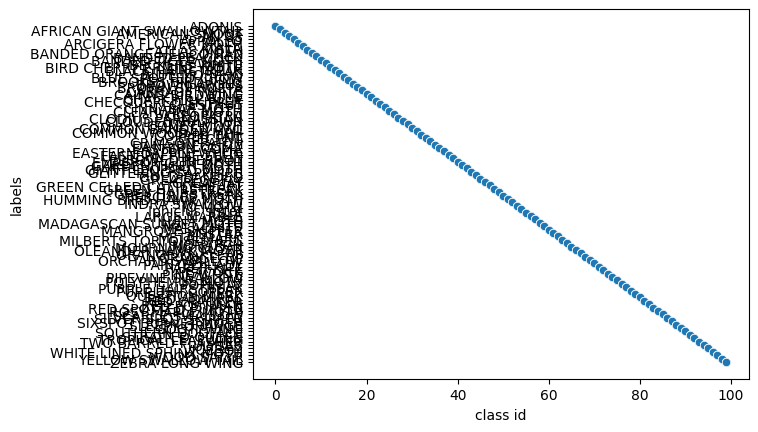

In [93]:
sns.scatterplot(data=df, x='class id', y='labels')
plt.show()

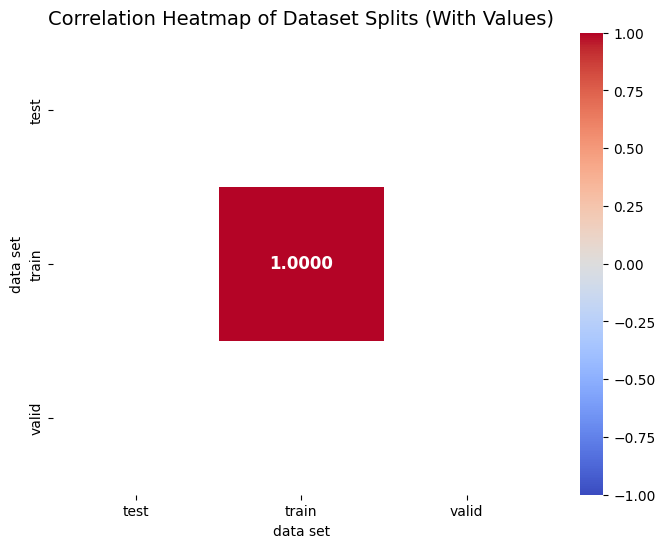

In [94]:
plt.figure(figsize=(8, 6))

# Create a cross-tabulation distribution matrix first
distribution_matrix = pd.crosstab(df['labels'], df['data set'])

# Compute correlation between the dataset splits (train, test, valid) and plot with clear value annotations
sns.heatmap(
    distribution_matrix.corr(),
    annot=True,
    fmt='.4f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    annot_kws={'size': 12, 'weight': 'bold'}
)

plt.title('Correlation Heatmap of Dataset Splits (With Values)', fontsize=14)
plt.show()

In [95]:
# Check unique counts per label
label_counts = df['labels'].value_counts()
display(label_counts)

,count
labels,
MOURNING CLOAK,197
GREEN HAIRSTREAK,186
BROWN ARGUS,179
BROOKES BIRDWING,175
SLEEPY ORANGE,162
...,...
GOLD BANDED,114
CRIMSON PATCH,113
MALACHITE,113


In [96]:
df.select_dtypes(include = 'object').columns


Index(['filepaths', 'labels', 'data set'], dtype='object')

In [97]:
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include = 'object').columns:
     df[col] = df[col].str.strip()


In [98]:
df['filepaths'] = df['filepaths'].map({'Yes': 1, 'No': 0})

In [99]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13594 entries, 0 to 13593
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   class id   13594 non-null  float64
 1   filepaths  0 non-null      float64
 2   labels     13594 non-null  object 
 3   data set   13594 non-null  object 
dtypes: float64(2), object(2)
memory usage: 424.9+ KB


In [100]:
pip install ucimlrepo

In [101]:
# Dataset ID 120 (E. Coli Genes) exists in the UCI repository but cannot be fetched programmatically via ucimlrepo.
# You can choose a compatible dataset from: https://archive.ics.uci.edu/datasets?Python=true

# Example of a valid import (e.g., Iris dataset with ID 59):
# from ucimlrepo import fetch_ucirepo
# iris = fetch_ucirepo(id=59)
# x = iris.features
# y = iris.targets

In [102]:
# Reload the butterflies dataset cleanly to recover the original filepaths and columns
df = pd.read_csv('/content/butterflies and moths.csv')

# Strip whitespaces from column names and string values
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Display the dataset summary to continue working on butterflies and moths
display(df.head())
df.info()

,class id,filepaths,labels,data set
0,0,train/ADONIS/001.jpg,ADONIS,train
1,0,train/ADONIS/002.jpg,ADONIS,train
2,0,train/ADONIS/003.jpg,ADONIS,train
3,0,train/ADONIS/004.jpg,ADONIS,train
4,0,train/ADONIS/005.jpg,ADONIS,train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13594 entries, 0 to 13593
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   class id   13594 non-null  int64 
 1   filepaths  13594 non-null  object
 2   labels     13594 non-null  object
 3   data set   13594 non-null  object
dtypes: int64(1), object(3)
memory usage: 424.9+ KB


In [103]:
from google.colab import data_table
import vega_datasets

data_table.enable_dataframe_formatter()

vega_datasets.data.airports()

,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944
...,...,...,...,...,...,...,...
3371,ZEF,Elkin Municipal,Elkin,NC,USA,36.280024,-80.786069
3372,ZER,Schuylkill Cty/Joe Zerbey,Pottsville,PA,USA,40.706449,-76.373147
3373,ZPH,Zephyrhills Municipal,Zephyrhills,FL,USA,28.228065,-82.155916
3374,ZUN,Black Rock,Zuni,NM,USA,35.083227,-108.791777


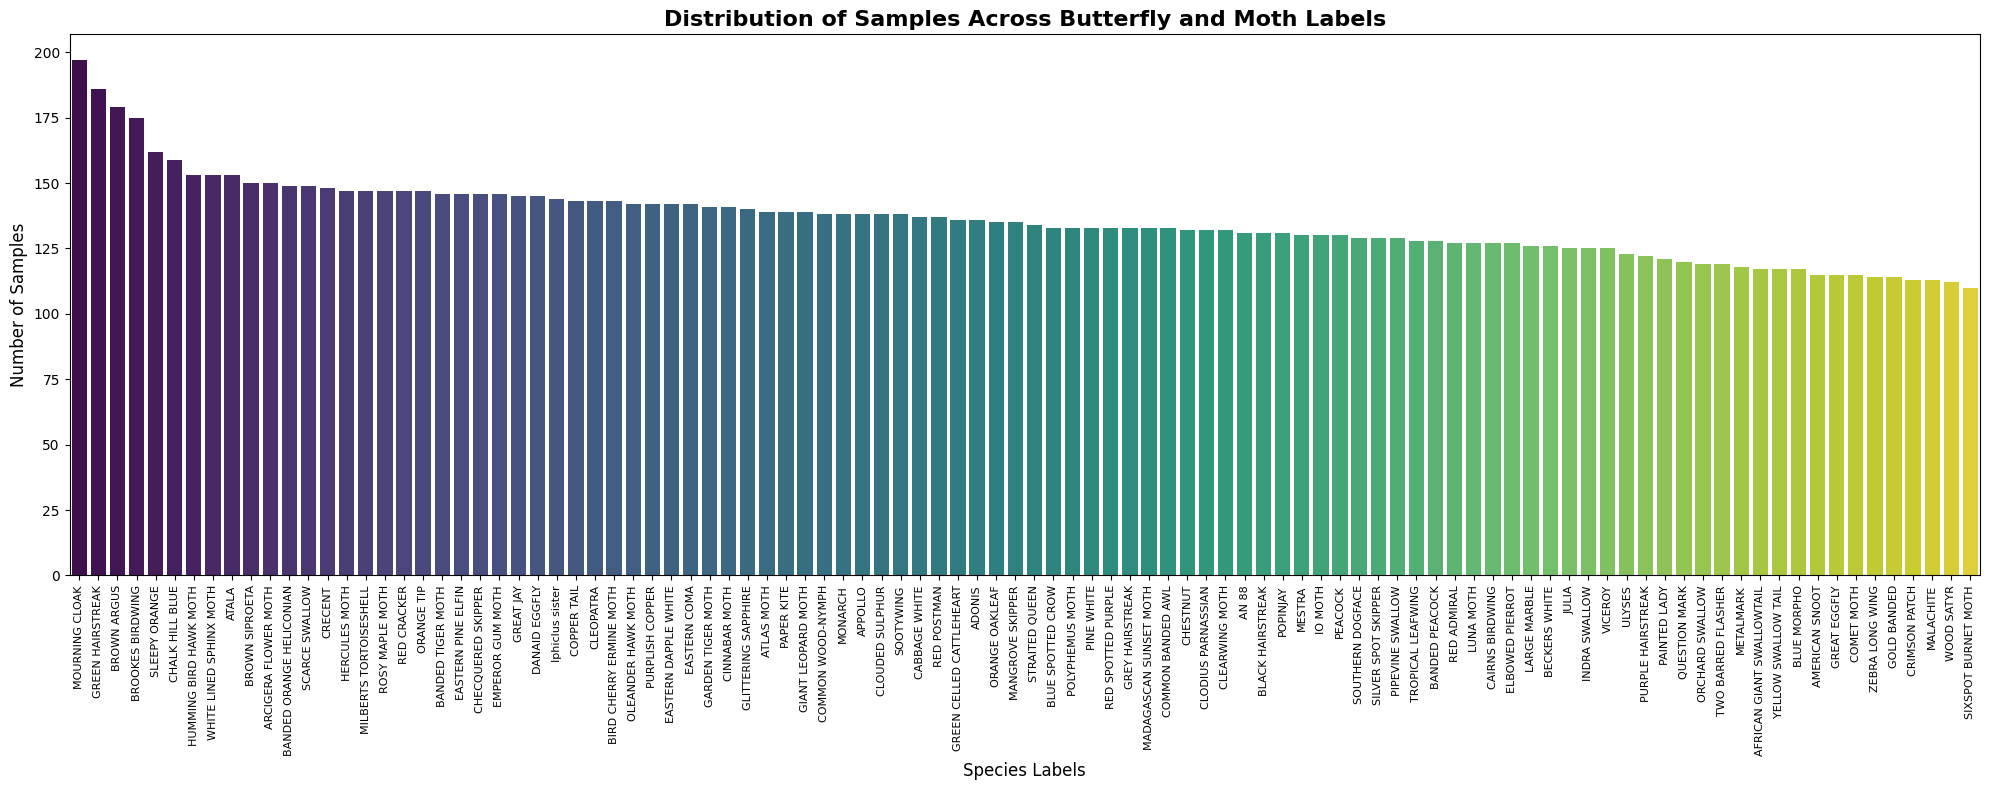

In [104]:
# Calculate the distribution of samples across labels
label_counts = df['labels'].value_counts().reset_index()
label_counts.columns = ['Label', 'Count']

# Create a bar chart
plt.figure(figsize=(20, 8))
sns.barplot(data=label_counts, x='Label', y='Count', palette='viridis', hue='Label', legend=False)
plt.title('Distribution of Samples Across Butterfly and Moth Labels', fontsize=16, fontweight='bold')
plt.xlabel('Species Labels', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)

# Rotate the x-axis labels to prevent overlapping
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

In [105]:
# The variable name was invalid. Since we already have the local CSV loaded in 'df',
# we can define features (X) and targets (y) directly from our butterflies and moths dataframe.

# Features (everything except the label/target columns)
X = df[['filepaths', 'data set']]

# Target (the species label)
y = df['labels']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (13594, 2)
Target shape: (13594,)


In [106]:
# Get unique values from the 'labels' column
unique_labels = df['labels'].unique()
unique_labels.sort()  # Sort them alphabetically for easier reading

print(f"Found {len(unique_labels)} unique species:")
print(unique_labels)

Found 100 unique species:
['ADONIS' 'AFRICAN GIANT SWALLOWTAIL' 'AMERICAN SNOOT' 'AN 88' 'APPOLLO'
 'ARCIGERA FLOWER MOTH' 'ATALA' 'ATLAS MOTH' 'BANDED ORANGE HELICONIAN'
 'BANDED PEACOCK' 'BANDED TIGER MOTH' 'BECKERS WHITE'
 'BIRD CHERRY ERMINE MOTH' 'BLACK HAIRSTREAK' 'BLUE MORPHO'
 'BLUE SPOTTED CROW' 'BROOKES BIRDWING' 'BROWN ARGUS' 'BROWN SIPROETA'
 'CABBAGE WHITE' 'CAIRNS BIRDWING' 'CHALK HILL BLUE' 'CHECQUERED SKIPPER'
 'CHESTNUT' 'CINNABAR MOTH' 'CLEARWING MOTH' 'CLEOPATRA'
 'CLODIUS PARNASSIAN' 'CLOUDED SULPHUR' 'COMET MOTH' 'COMMON BANDED AWL'
 'COMMON WOOD-NYMPH' 'COPPER TAIL' 'CRECENT' 'CRIMSON PATCH'
 'DANAID EGGFLY' 'EASTERN COMA' 'EASTERN DAPPLE WHITE'
 'EASTERN PINE ELFIN' 'ELBOWED PIERROT' 'EMPEROR GUM MOTH'
 'GARDEN TIGER MOTH' 'GIANT LEOPARD MOTH' 'GLITTERING SAPPHIRE'
 'GOLD BANDED' 'GREAT EGGFLY' 'GREAT JAY' 'GREEN CELLED CATTLEHEART'
 'GREEN HAIRSTREAK' 'GREY HAIRSTREAK' 'HERCULES MOTH'
 'HUMMING BIRD HAWK MOTH' 'INDRA SWALLOW' 'IO MOTH' 'Iphiclus sister'
 'JULIA'

In [107]:
import pandas as pd
df = pd.read_csv('/content/butterflies and moths.csv')
df.head()

,class id,filepaths,labels,data set
0,0,train/ADONIS/001.jpg,ADONIS,train
1,0,train/ADONIS/002.jpg,ADONIS,train
2,0,train/ADONIS/003.jpg,ADONIS,train
3,0,train/ADONIS/004.jpg,ADONIS,train
4,0,train/ADONIS/005.jpg,ADONIS,train


In [108]:
from google.colab import data_table
import vega_datasets

data_table.enable_dataframe_formatter()

vega_datasets.data.airports()

,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944
...,...,...,...,...,...,...,...
3371,ZEF,Elkin Municipal,Elkin,NC,USA,36.280024,-80.786069
3372,ZER,Schuylkill Cty/Joe Zerbey,Pottsville,PA,USA,40.706449,-76.373147
3373,ZPH,Zephyrhills Municipal,Zephyrhills,FL,USA,28.228065,-82.155916
3374,ZUN,Black Rock,Zuni,NM,USA,35.083227,-108.791777


In [115]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13594 entries, 0 to 13593
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   class id   13594 non-null  int64 
 1   filepaths  13594 non-null  object
 2   labels     13594 non-null  object
 3   data set   13594 non-null  object
dtypes: int64(1), object(3)
memory usage: 424.9+ KB
